# Parametric Vector Fitting Of An Inductor
As an example for the application of parametric vector fitting, a set of electromagnetic simulations of an inductor is given. The inductors are simulated for different diameters $D = [80, 100, 120, 140, 160, 180, 200]$ µm. For this demonstration, the fitting process will be based on just a subset $D_\mathrm{fit} = [80, 120, 160, 200]$ µm. The remaining datapoints will be used later to assess the fit accuracy at $D_\mathrm{check} = [100, 140, 180]$ µm.

In the following, a typical workflow to create and use the parametric model is demonstrated.

## Create a NetworkSet
The individual simulation files need to be loaded and grouped into a labelled NetworkSet.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from skrf.network import Network
from skrf.networkSet import NetworkSet
from skrf.vectorFitting import VectorFittingParametric

networks = [Network('spiral_D80.s2p', params={'D': 80}),
            Network('spiral_D120.s2p', params={'D': 120}),
            Network('spiral_D160.s2p', params={'D': 160}),
            Network('spiral_D200.s2p', params={'D': 200})]
nwset = NetworkSet(networks)

## Initialize and run the fitting process
These particular networks turned out to be overly sensitive to the initial pole setup for the vector fitting process. For most networks, the automatic pole initialization (with `n_poles_real=-1, n_poles_cmplx=-1` will work well. Here, we have to specify `n_poles_real=3, n_poles_cmplx=0`:

In [2]:
vf = VectorFittingParametric(nwset, n_poles_real=3, n_poles_cmplx=0)
vf.auto_fit()

/home/alex/code/scikit-rf-docs/skrf/vectorFitting.py:2813: UserWarning: Passivity enforcement: The dc point in the model is not passive. Cannot preserve the dc point during passivity enforcement. 
  vf.passivity_enforce()


## Use the model

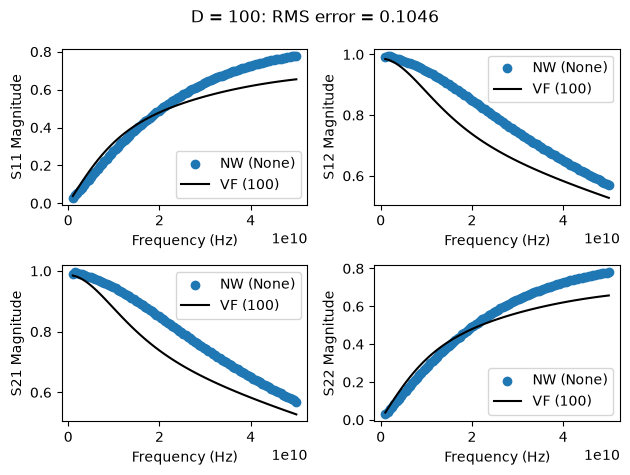

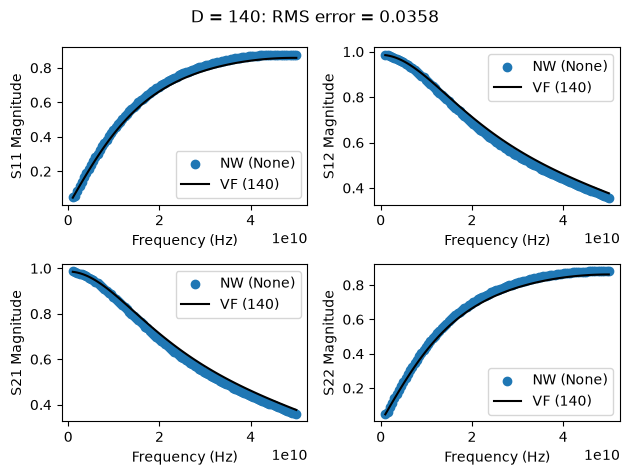

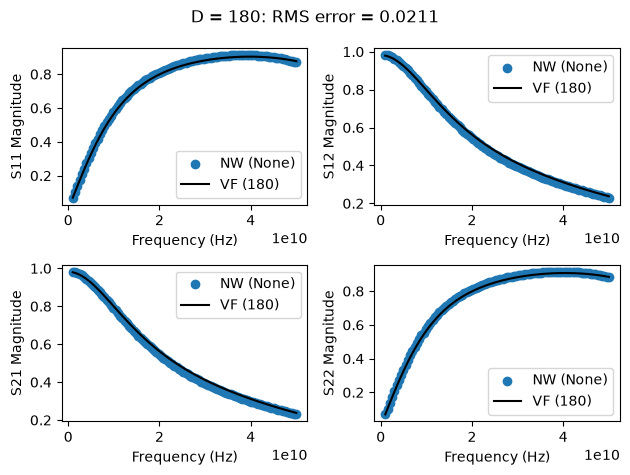

In [3]:
for d_check in [100, 140, 180]:
    nw = Network(f'spiral_D{d_check}.s2p')
    model = vf.get_model_response({'D': d_check}, nw.f)
    error = np.sqrt(np.mean(np.square(np.abs(model - nw.s))))

    n_ports = nw.nports
    fig, ax = plt.subplots(n_ports, n_ports)
    fig.suptitle(f'D = {d_check}: RMS error = {error:.4f}')
    for i in range(n_ports):
        for j in range(n_ports):
            ax[i][j].scatter(nw.f, np.abs(nw.s[:, i, j]), label=f'NW ({nw.params})')
            ax[i][j].plot(nw.f, np.abs(model[:, i, j]), color='k', label=f'VF ({d_check})')
            ax[i][j].legend()
            ax[i][j].set_xlabel('Frequency (Hz)')
            ax[i][j].set_ylabel(f'S{i+1}{j+1} Magnitude')
    fig.tight_layout()
    plt.show()